# Data augmentation for MNIST

Hentet fra Puneet sin [GitHub](https://github.com/puneetnorge/Machine-Vision/blob/main/LeNet_5_MNIST_changing_the_percentTrainData.ipynb) side

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset, TensorDataset
import torchvision


Numpy gjør det ekstremt mye enklere å jobbe med matriser.
Pandas lager tabeller og lagrer resultater.
Matplotlib tegner plott
Torch er selve maskinlæringsbibliotenet

#### LeNet5
LeNet5 er selve modellen. Den får et blide på 28x28 piksler dyttet inn, og dytter ut ti tall, der det høyeste tallet er modellens gjettning.

In [2]:
class LeNet5(nn.Module):
    def __init__(self, num_of_classes, p): # 'p' probability of an element being zeroed out
        # Initialize the parent class (nn.Module)
        super(LeNet5, self).__init__()

        # Layer 1: Convolutional + BatchNorm2D  +  Pooling
        ''' we are using three channels as input (instead of 1) for some experiments that will be done later '''
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=1, padding=2)  # 28x28 -> 28x28
        self.bn1 = nn.BatchNorm2d(6)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)  # 28x28 -> 14x14
        # Layer 2: Convolutional + BatchNorm2D + Pooling
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1)  # 14x14 -> 10x10
        self.bn2 = nn.BatchNorm2d(16)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)  # 10x10 -> 5x5
        # Layer 3: Fully Connected + BatchNorm1D
        self.fc1 = nn.Linear(in_features=16*5*5, out_features=120)
        self.bn3 = nn.BatchNorm1d(120)
        # Layer 4: Fully Connected + BatchNorm1D
        self.fc2 = nn.Linear(in_features=120, out_features=84)
        self.bn4 = nn.BatchNorm1d(84)
        # Layer 5: Output Layer
        self.fc3 = nn.Linear(in_features=84, out_features=num_of_classes)
        # Dropout layers
        self.dropout = nn.Dropout(p)  # dropout layer defined in __init__

    def forward(self, x):
        # Layer 1: Conv2 -> BatchNorm -> Pooling -> Activation
        x = F.relu(self.pool1(self.bn1(self.conv1(x))))

        # Layer 2: Conv2 -> BatchNorm -> Pooling -> Activation
        x = F.relu(self.pool2(self.bn2(self.conv2(x))))

        # Flatten the output from the convolutional layers
        x = x.view(-1, 16 * 5 * 5)
        # Layer 3: Fully Connected + BatchNorm + Activation
        x = F.relu(self.bn3(self.fc1(x)))
        # Apply dropout after first FC layer
        x = self.dropout(x)
        # Layer 4: Fully Connected +  BatchNorm + Activation
        x = F.relu(self.bn4(self.fc2(x)))
        # Apply dropout after second FC layer
        x = self.dropout(x)
        # Layer 5: Fully Connected (Output)
        x = self.fc3(x)
        return x

#### Device and loss

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

#### EarlyStopping

Lagrer den beste versjonen av modellen underveis (lavest valideringstap). Selve stoppingen er i praksis skrudd av (patience = num_epochs), slik at alle metodene trenes like lenge og treningsplottene blir direkte sammenlignbare.

In [4]:
class EarlyStopping:
    """
    Initializes the early stopping mechanism.

    Args:
        patience (int): Number of epochs to wait for improvement.
        delta (float): Minimum change in validation loss to qualify as improvement.

    """
    def __init__(self, patience, delta):
        self.patience = patience
        self.delta = delta
        self.best_score = None  # Tracks the best loss (lower is better)
        self.early_stop = False  # Flag for early stopping
        self.counter = 0  # Counter for epochs without improvement
        self.best_loss = np.inf  # Best loss starts as infinity

    ''' special method that allows us to use the object as if it were a function. '''
    def __call__(self, val_loss, model):
        """
        Training should be stopped early based on validation loss.

        Args:
            val_loss (float): Current epoch's validation loss.
            model (torch.nn.Module): Model to save if validation loss improves.
        """
        score = -val_loss  # Loss is used as the score (lower is better, so we negate it)

        # If this is the first epoch or loss improved significantly
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score - self.delta:
            # No significant improvement (i..e, loss hasn't decreased enough)
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            # Improvement in loss
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0  # Reset the counter if loss improves

    def save_checkpoint(self, val_loss, model):
        """
        Save the model when validation loss improves.

        Args:
            val_loss (float): Current epoch's validation loss.
            model (torch.nn.Module): Model to save if validation loss improves.
        """
        if val_loss < self.best_loss:  # We save if loss decreased
            self.best_loss = val_loss
            checkpoint_name = "checkpoint.pth"
            torch.save(model.state_dict(), checkpoint_name)
            print(f'Model saved as {checkpoint_name}')

#### Train model
Denne funksjonen er det som utfører selve treningen(en epoke om gangen).

In [5]:
## A method to train the model and return train and validation metrics
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
  early_stopping = EarlyStopping(patience=num_epochs, delta=0.0001)  # Stopper aldri, lagrer bare beste modell

  # epoch = 0       <--- ???

  history = {'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': []}

  for epoch in range(num_epochs):
      model.train()
      running_loss = 0.0
      correct = 0
      total = 0
      for inputs, labels in train_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          optimizer.zero_grad()
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()
          running_loss += loss.item()
          _, predicted = torch.max(outputs, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()
      train_loss = running_loss / len(train_loader)
      train_accuracy = 100 * correct / total

      # .eval indicates that the model is used for prediction.
      model.eval()
      val_loss = 0.0
      correct = 0
      total = 0
      with torch.no_grad():
          for inputs, labels in val_loader:
              inputs, labels = inputs.to(device), labels.to(device)
              outputs = model(inputs)
              loss = criterion(outputs, labels)
              val_loss += loss.item()
              _, predicted = torch.max(outputs, 1)
              total += labels.size(0)
              correct += (predicted == labels).sum().item()
      val_loss /= len(val_loader)

      val_accuracy = 100 * correct / total
      print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')

      history['train_loss'].append(train_loss)
      history['val_loss'].append(val_loss)
      history['train_accuracy'].append(train_accuracy)
      history['val_accuracy'].append(val_accuracy)

      early_stopping(val_loss, model)

      if early_stopping.early_stop:
        print("Early stopping")
        break
  return history

#### Test modell

In [6]:
def test_model(model, test_loader, criterion, device):
  # Testing load the model with best validation from checkpoint
  model.load_state_dict(torch.load("checkpoint.pth",weights_only=True))
  model.to(device)
  model.eval()
  test_loss = 0.0
  correct = 0
  total = 0
  with torch.no_grad():
      for inputs, labels in test_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          test_loss += loss.item()
          _, predicted = torch.max(outputs, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()
  test_loss /= len(test_loader)
  test_accuracy = 100 * correct / total

  print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%')
  return test_loss, test_accuracy

#### Data og transforms

In [7]:
num_epochs      = 25
percent_train   = 10    # Lite data gjør effekten tydeligere

transform_test = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.Grayscale(num_output_channels=3),  # Convert grayscale to RGB by repeating channels
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

def make_transform(aug):
    return transforms.Compose([
        transforms.Resize((28, 28)),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        *aug,  # Etter ToTensor, siden RandomErasing (Cutout) bare virker på tensorer
        transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
    ])

full_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform_test)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform_test)

torch.manual_seed(42)
idx = torch.randperm(len(full_train))
val_idx = idx[:12000]
train_idx = idx[12000:12000 + int(percent_train / 100 * 48000)]


def til_tensorer(dataset):
    # Kjører alle bildene gjennom transform én gang og lagrer resultatet
    x = torch.stack([img for img, _ in dataset])
    y = torch.tensor([label for _, label in dataset])
    return TensorDataset(x, y)

val_loader = DataLoader(til_tensorer(Subset(full_train, val_idx)), batch_size=1000, shuffle=False)
test_loader = DataLoader(til_tensorer(test_dataset), batch_size=1000, shuffle=False)

100.0%
100.0%
100.0%
100.0%


#### Testing og eksperimentering

In [8]:
experiments = {
    'Original':          [],
    'Rotasjon 15':       [transforms.RandomRotation(15)],
    'Rotasjon 45':       [transforms.RandomRotation(45)],
    'Forskyvning 10%':   [transforms.RandomAffine(0, translate=(0.1, 0.1))],
    'Forskyvning 25%':   [transforms.RandomAffine(0, translate=(0.25, 0.25))],
    'Skalering 0.9-1.1': [transforms.RandomAffine(0, scale=(0.9, 1.1))],
    'Skalering 0.6-1.4': [transforms.RandomAffine(0, scale=(0.6, 1.4))],
    'Repo-kombo':        [transforms.RandomRotation(30), transforms.RandomAffine(0, translate=(0.1, 0.1))],
    'Speiling H':        [transforms.RandomHorizontalFlip(p=1)],
    'Speiling V':        [transforms.RandomVerticalFlip(p=1)],
    'Rotasjon 180':      [transforms.RandomRotation(180)],
    'Cutout liten':      [transforms.RandomErasing(p=0.5, scale=(0.02, 0.1), ratio=(1, 1), value=0)],
    'Cutout stor':       [transforms.RandomErasing(p=0.5, scale=(0.1, 0.25), ratio=(1, 1), value=0)],
}

#### Se hva augmenteringene gjør
Merk: Fått hjelp med kodingen for resterende kode av claude

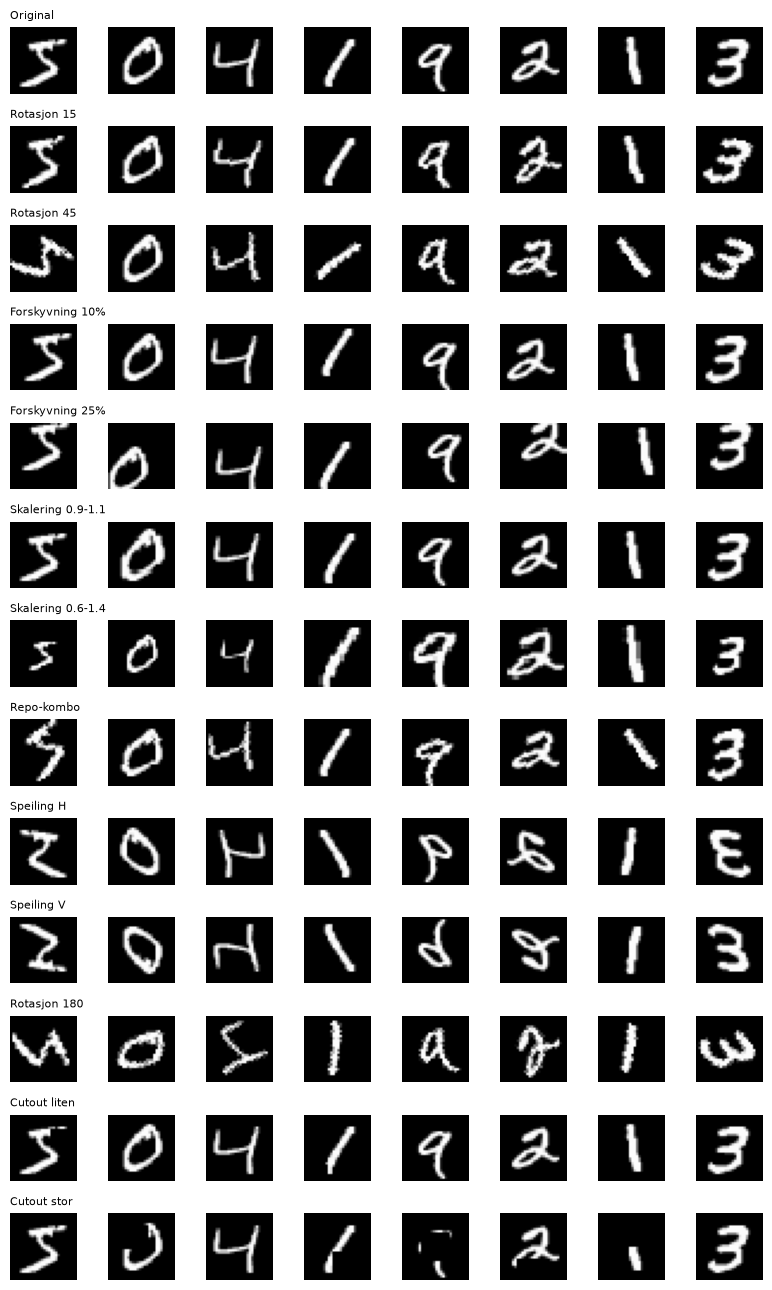

In [9]:
fig, axes = plt.subplots(len(experiments), 8, figsize=(8, len(experiments)))
for row, (name, aug) in enumerate(experiments.items()):
    ds = datasets.MNIST(root='./data', train=True, transform=make_transform(aug))
    for col in range(8):
        img, _ = ds[col]
        axes[row, col].imshow(img[0] * 0.5 + 0.5, cmap='gray')
        axes[row, col].axis('off')
    axes[row, 0].set_title(name, fontsize=8, loc='left')
plt.tight_layout()
plt.show()

#### Tren alt

In [10]:
import os
import time

results = pd.read_pickle('results.pkl') if os.path.exists('results.pkl') else {}
total = len(experiments)

for i, (name, aug) in enumerate(experiments.items(), start=1):
    if os.path.exists(f'model_{name}.pth'):
        print(f'[{i}/{total}] {name}: ferdig fra før, hopper over')
        continue

    print(f'\n===== [{i}/{total}] {name} =====')
    start = time.time()

    train_set = datasets.MNIST(root='./data', train=True, transform=make_transform(aug))
    train_loader = DataLoader(Subset(train_set, train_idx), batch_size=128, shuffle=True, num_workers=2, persistent_workers=True)

    model = LeNet5(num_of_classes=10, p=0.5).to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0005)

    h = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device)
    h['test_loss'], h['test_acc'] = test_model(model, test_loader, criterion, device)
    results[name] = h

    torch.save(model.state_dict(), f'model_{name}.pth')
    pd.to_pickle(results, 'results.pkl')
    print(f'Ferdig på {(time.time() - start) / 60:.1f} min, lagret til fil')


===== [1/13] Original =====
Epoch 1/25, Train Loss: 1.5759, Train Accuracy: 53.79%, Val Loss: 1.0108, Val Accuracy: 83.71%
Model saved as checkpoint.pth
Epoch 2/25, Train Loss: 0.8476, Train Accuracy: 82.92%, Val Loss: 0.4884, Val Accuracy: 90.88%
Model saved as checkpoint.pth
Epoch 3/25, Train Loss: 0.5189, Train Accuracy: 90.42%, Val Loss: 0.2755, Val Accuracy: 95.13%
Model saved as checkpoint.pth
Epoch 4/25, Train Loss: 0.3653, Train Accuracy: 92.69%, Val Loss: 0.2257, Val Accuracy: 95.32%
Model saved as checkpoint.pth
Epoch 5/25, Train Loss: 0.2851, Train Accuracy: 94.04%, Val Loss: 0.1602, Val Accuracy: 96.12%
Model saved as checkpoint.pth
Epoch 6/25, Train Loss: 0.2327, Train Accuracy: 95.21%, Val Loss: 0.1665, Val Accuracy: 96.08%
EarlyStopping counter: 1 out of 25
Epoch 7/25, Train Loss: 0.1862, Train Accuracy: 96.15%, Val Loss: 0.1206, Val Accuracy: 96.75%
Model saved as checkpoint.pth
Epoch 8/25, Train Loss: 0.1730, Train Accuracy: 95.85%, Val Loss: 0.1173, Val Accuracy: 96.

#### Treningsplott per metode

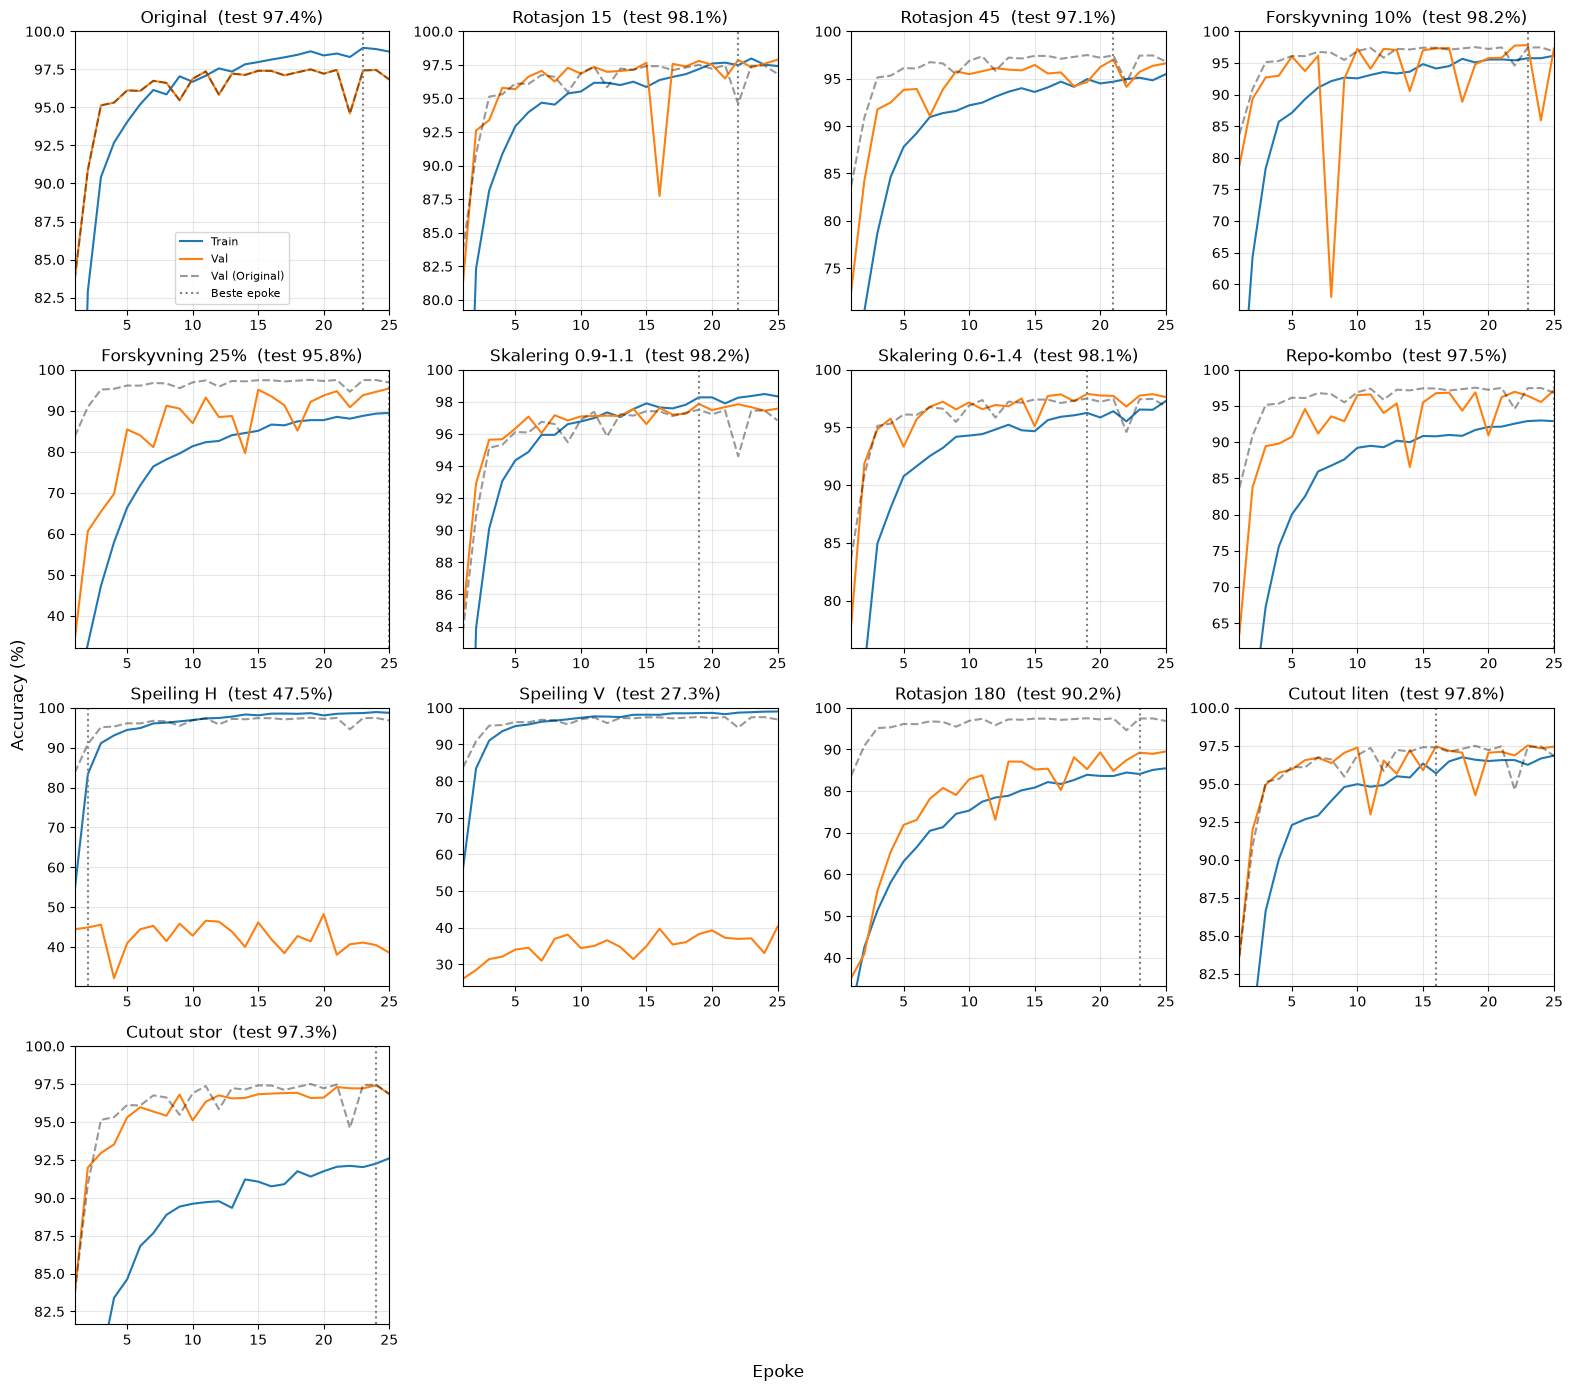

In [11]:
ref = results['Original']
rows = -(-len(results) // 4)  # Antall rader, rundet opp
fig, axes = plt.subplots(rows, 4, figsize=(16, 3.5 * rows))
for ax, (name, h) in zip(axes.flat, results.items()):
    epoker = range(1, len(h['val_accuracy']) + 1)
    beste = h['val_loss'].index(min(h['val_loss'])) + 1  # Epoken som ble lagret i checkpoint

    ax.plot(epoker, h['train_accuracy'], label='Train')
    ax.plot(epoker, h['val_accuracy'], label='Val')
    ax.plot(range(1, len(ref['val_accuracy']) + 1), ref['val_accuracy'], 'k--', alpha=0.4, label='Val (Original)')
    ax.axvline(beste, color='gray', linestyle=':', label='Beste epoke')

    ax.set_title(f"{name}  (test {h['test_acc']:.1f}%)")
    ax.set_xlim(1, num_epochs)
    ax.set_ylim(min(90, min(h['val_accuracy']) - 2), 100)  # Zoomet inn, men plass til de dårlige
    ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)
for ax in axes.flat[len(results):]:
    ax.axis('off')
fig.supxlabel('Epoke')
fig.supylabel('Accuracy (%)')
plt.tight_layout()
plt.show()

#### All validering i ett plott

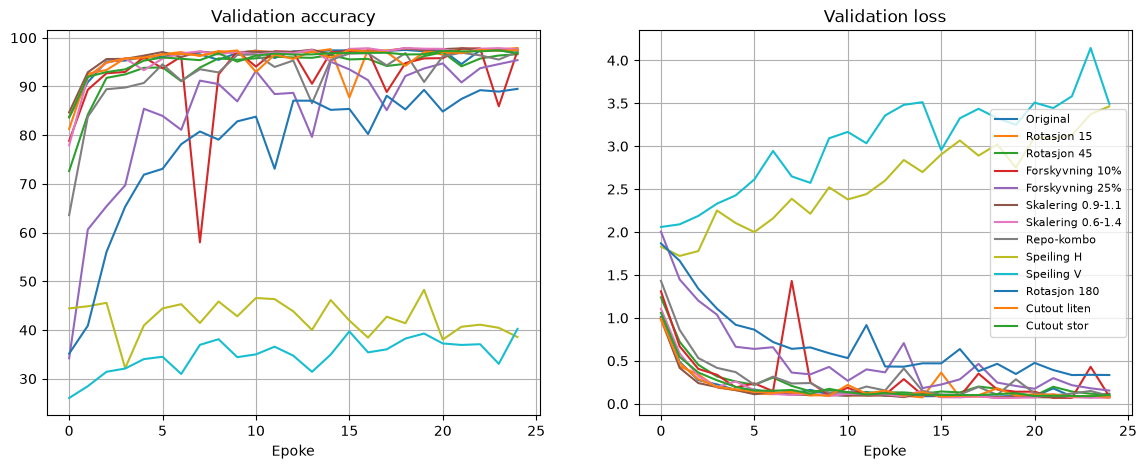

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, h in results.items():
    axes[0].plot(h['val_accuracy'], label=name)
    axes[1].plot(h['val_loss'], label=name)
axes[0].set_title('Validation accuracy')
axes[1].set_title('Validation loss')
for ax in axes:
    ax.set_xlabel('Epoke')
    ax.grid()
axes[1].legend(fontsize=8)
plt.show()

#### Oppsmeringstabell + stolpediagram

,Test acc,Beste val acc,Gap train-val,Epoker
Skalering 0.9-1.1,98.22,97.87,0.77,25.0
Forskyvning 10%,98.16,97.82,-1.17,25.0
Skalering 0.6-1.4,98.12,97.90,-0.35,25.0
Rotasjon 15,98.09,97.89,-0.47,25.0
Cutout liten,97.81,97.52,-0.60,25.0
Repo-kombo,97.46,97.12,-4.25,25.0
Original,97.41,97.50,1.83,25.0
Cutout stor,97.31,97.42,-4.25,25.0
Rotasjon 45,97.14,97.02,-1.14,25.0
Forskyvning 25%,95.75,95.40,-5.96,25.0


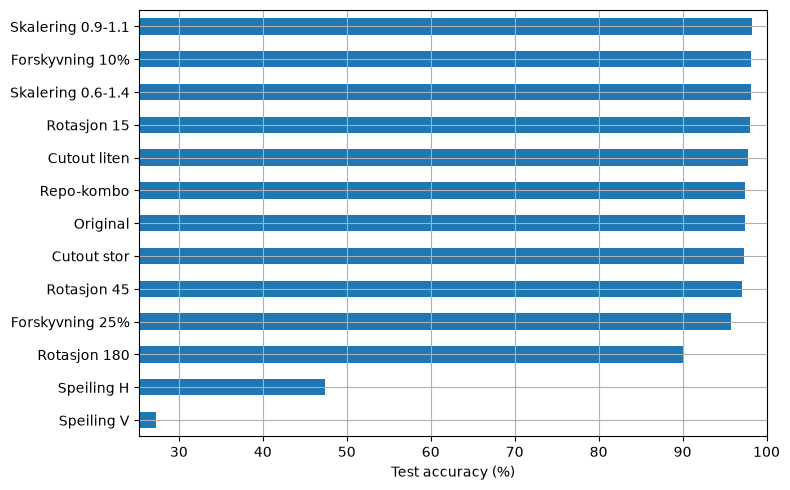

In [13]:
df = pd.DataFrame({
    name: {
        'Test acc': h['test_acc'],
        'Beste val acc': max(h['val_accuracy']),
        'Gap train-val': h['train_accuracy'][-1] - h['val_accuracy'][-1],
        'Epoker': len(h['val_accuracy']),
    }
    for name, h in results.items()
}).T.round(2).sort_values('Test acc', ascending=False)
display(df)

df['Test acc'].plot.barh(figsize=(8, 5), xlim=(df['Test acc'].min() - 2, 100), grid=True)
plt.xlabel('Test accuracy (%)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()